5
[0, 5, 9, 11, 1] [array([1000.,  700.]), array([810.57377468, 486.17108677]), array([677., 325.]), array([355.94549682, 137.26709127]), array([1., 1.])]


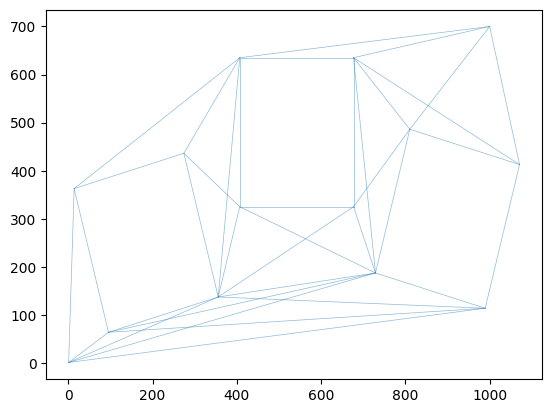

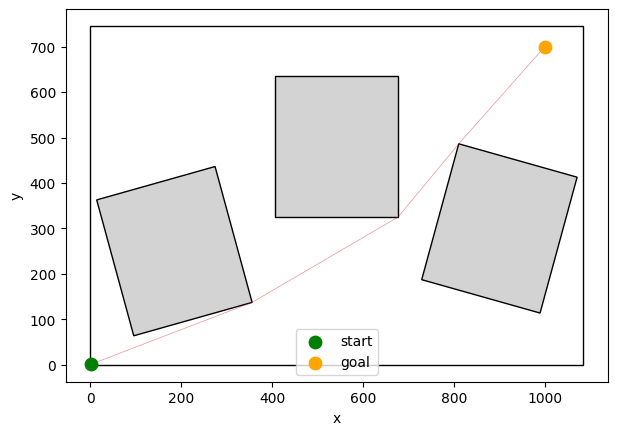

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from shapely.geometry import LineString, Polygon
import heapq

ob1 = [(176, 206), (215, 217), (194, 294), (155, 283)]
ob2 = [(522, 440), (562, 440), (562, 520), (522, 520)]
ob3 = [(870, 267), (909, 256), (930, 333), (891, 344)]

start = (1, 1)
goal = (1000, 700)
raw_obstacles = (ob1, ob2, ob3)
# start is Node 0, goal is Node 1, everything else are the vertices
# nodes = [start, goal] + ob1 + ob2 + ob3
# nodes = np.array(nodes) 
boundary = [(0, 0),
            (1085, 0),
            (1085, 745), 
            (0, 745)]

def grow_obstacles(obstacles, pad):
    grown = []
    for ob in obstacles:
        poly = Polygon(ob).buffer(pad, join_style="mitre", mitre_limit=10)
        grown.append(list(poly.exterior.coords)[:-1])   # drop the repeated closing point
    return grown

def plot_visibility_graph(obstacles, start, goal, boundary):
    fig, ax = plt.subplots(figsize=(7, 7))

    # 1. obstacles, straight from the vertex lists
    for verts in obstacles:
        ax.add_patch(MplPolygon(verts, closed=True,
                                facecolor="lightgray", edgecolor="black"))
        
    ax.add_patch(MplPolygon(boundary, closed=True, fill=False, edgecolor="black"))

    ax.scatter(*start, s=80, color="green", zorder=4, label="start")
    ax.scatter(*goal, s=80, color="orange", zorder=4, label="goal")
    

    ax.set_aspect("equal")        # keeps angles and lengths undistorted
    ax.autoscale_view()
    ax.legend()
    ax.set_xlabel("x"); ax.set_ylabel("y")

def is_visible(a, b, obstacles, boundary):
    seg = LineString([a, b])
    polys = [Polygon(v) for v in obstacles]
    bounds = Polygon(boundary)

    if not bounds.contains(seg):
        return False
    
    for poly in polys:
        # blocked if the segment cuts through the interior;
        # touching a vertex or sliding along an edge is allowed
        if seg.crosses(poly) or seg.within(poly) or seg.crosses(bounds):
            return False
    return True

def plot_path_options(nodes, boundary, obstacles):
    num_nodes = len(nodes)
    neighbors = [[] for _ in range(num_nodes)]

    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            if is_visible(nodes[i, :], nodes[j, :], obstacles, boundary):
                neighbors[i].append(j)
                neighbors[j].append(i)
                plt.plot([nodes[i, 0], nodes[j, 0]],
                     [nodes[i, 1], nodes[j, 1]],
                     color="tab:blue", linewidth=0.5, alpha=0.5)
    return neighbors

def map_distances(nodes):
    num_nodes = nodes.shape[0]
    distance = np.zeros((num_nodes, num_nodes))

    for i in range(num_nodes):
        for j in range(num_nodes):
            if i != j:
                distance[i, j] = np.linalg.norm(nodes[i] - nodes[j], ord=2)
            else:
                distance[i, j] = 0
    return distance 

def calc_heuristic(nodes):
    num_nodes = nodes.shape[0]
    heuristic = np.zeros(num_nodes)
    for i in range(num_nodes):
        heuristic[i] = np.linalg.norm(nodes[i] - nodes[2], ord=2)
    return heuristic

def path_search(nodes, neighbors, distance, start=0, goal=1):
    nodes = np.asarray(nodes)
    goal_pos = nodes[goal]

    def h(i):
        return float(np.linalg.norm(nodes[i] - goal_pos))

    open_heap = [(h(start), start)]    # (f, node)
    came_from = {}
    g = {start: 0.0}
    closed = set()
    explored = []
    operation_count = 0

    while open_heap:
        f, current = heapq.heappop(open_heap)
        if current in closed:
            continue                    # stale heap entry
        closed.add(current)
        explored.append(current)
        operation_count += 1

        if current == goal:
            path = [current]
            path_coords = []
            while current in came_from:
                current = came_from[current]
                path.append(current)
            for i in range(operation_count-1):
                path_coords.append(nodes[path[i]])
            return path[::-1], g[goal], explored, operation_count, path_coords

        for nb in neighbors[current]:
            if nb in closed:
                continue
            tentative = g[current] + distance[current][nb]
            if tentative < g.get(nb, float("inf")):
                g[nb] = tentative
                came_from[nb] = current
                heapq.heappush(open_heap, (tentative + h(nb), nb))

    return None, float("inf"), explored, operation_count   # no path found

def plot_route(path, obstacles, start, goal, nodes, boundary):
    plot_visibility_graph(obstacles, start, goal, boundary)
    print(len(path))
    for i in range(len(path) - 1):
        plt.plot([nodes[path[i], 0], nodes[path[i+1], 0]],
                     [nodes[path[i], 1], nodes[path[i+1], 1]],
                     color="tab:red", linewidth=0.5, alpha=0.5)

def run_global_nav(start, goal, raw_obstacles):
    obstacles = grow_obstacles(raw_obstacles, 115)
    nodes = np.array([start, goal] + [v for ob in obstacles for v in ob])
    neighbors = plot_path_options(nodes, boundary, obstacles)
    distance = map_distances(nodes)
    heuristic = calc_heuristic(nodes)
    path, cost, explored, ops, coords = path_search(nodes, neighbors, distance)

    plot_route(path, obstacles, start, goal, nodes, boundary)
    return path, coords
    
path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

In [32]:
%pip install shapely

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [29]:
def path_search(nodes, neighbors, distance, start=0, goal=1):
    nodes = np.asarray(nodes)
    goal_pos = nodes[goal]

    def h(i):
        return float(np.linalg.norm(nodes[i] - goal_pos))

    open_heap = [(h(start), start)]    # (f, node)
    came_from = {}
    g = {start: 0.0}
    closed = set()
    explored = []
    operation_count = 0

    while open_heap:
        f, current = heapq.heappop(open_heap)
        if current in closed:
            continue                    # stale heap entry
        closed.add(current)
        explored.append(current)
        operation_count += 1

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            return path[::-1], g[goal], explored, operation_count

        for nb in neighbors[current]:
            if nb in closed:
                continue
            tentative = g[current] + distance[current][nb]
            if tentative < g.get(nb, float("inf")):
                g[nb] = tentative
                came_from[nb] = current
                heapq.heappush(open_heap, (tentative + h(nb), nb))

    return None, float("inf"), explored, operation_count   # no path found

path, cost, explored, ops = path_search(nodes, neighbors, distance)
print(path, cost)

[0, 11, 1] 13.906117087056183


In [ ]:
def grid_search(map_grid, S, G, algo="Dijkstra"):
    
    # TODO initialize the variables suggested above
    came_from = {}      # to reconstruct path
    g_costs = {S: 0}    # cost from start to the cell
    explored = set()    # to keep track of explored cells
    operation_count = 0 # to count the number of operations
   
    if algo == "Dijkstra":
        open_set = [(0, S)] # priority queue for Dijkstra (cost, position)
    if algo == "A*": #fill in later for the A* algorithm
        open_set = [(heuristic(S, G), 0, S)]
        
    while open_set: # G goal is unmarked
        if algo == "Dijkstra":
            current_g_cost, current_pos = heappop(open_set)
        if algo == "A*":  #fill in later
            current_f_cost, current_g_cost, current_pos = heappop(open_set)

        explored.add(current_pos)
        
        # if G goal is marked --> break TODO
        if current_pos == G:
            break

        # Get neighbors (up, down, left, right) TODO
        neighbors = [
            (current_pos[0]-1, current_pos[1]), # UP
            (current_pos[0]+1, current_pos[1]), # DOWN
            (current_pos[0], current_pos[1]-1), # LEFT
            (current_pos[0], current_pos[1]+1)  # RIGHT
        ]

        for neighbor in neighbors: # for each neighbor of marked cells
            # Check if neighbor is within bounds
            if (0 <= neighbor[0] < map_grid.shape[0]) and (0 <= neighbor[1] < map_grid.shape[1]): 
                # Check if neighbor is not an obstacle
                if map_grid[neighbor[0], neighbor[1]] != -1: ##TODO
                    # Calculate tentative_g_cost TODO
                    tentative_g_cost = current_g_cost + 1  + map_grid[neighbor[0], neighbor[1]]

                    if neighbor not in g_costs or tentative_g_cost < g_costs[neighbor]: # Put the condition to add the tentative_g_cost to g_costs TODO
                        # Update the tentative_g_cost in g_costs TODO
                        g_costs[neighbor] = tentative_g_cost
                        # Update the came_from dictionary TODO
                        came_from[neighbor] = current_pos
                        operation_count += 1

                        if algo == "Dijkstra":
                            heappush(open_set, (tentative_g_cost, neighbor))

                        if algo == "A*": #fill in later
                            f_cost = heuristic(current_pos, G) # Calculate f_cost for A*
                            heappush(open_set, (f_cost, tentative_g_cost, neighbor))
                        
    #TODO: Reconstruct the path
    if current_pos == G: # what condition TODO?
        path = []
        while current_pos != S: # what condition TODO ?
            path.append(current_pos)
            current_pos = came_from[current_pos] #TODO
        path.append(S)
        path.reverse()
        #play with the operation_count if you want
        operation_count = 0
        return path, explored, operation_count  # Return reversed path and explored cells
    else:
    # If we reach here, no path was found
        return None, explored, operation_count